# ⚡ The VGC Meta-Gatekeeper
### Can a Pokémon's base stats and typing predict whether it shows up at the World Championships?

# EDA

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    log_loss,
    mean_squared_error,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler

In [20]:
path = r"../dataset/pokemon_competitive_analysis.csv"

try:
    d = pd.read_csv(path)
except FileNotFoundError:
    raise FileNotFoundError("CSV not found!).")

print("Shape (rows, columns):", d.shape)
d.head()

Shape (rows, columns): (1303, 23)


,index,name,type1,type2,ability1,ability2,hidden_ability,hp,attack,defense,...,total_stats,legendary,mythical,generation,Smogon_VGC_Usage_2022,Smogon_VGC_Usage_2023,Smogon_VGC_Usage_2024,Worlds_VGC_Usage_2022,Worlds_VGC_Usage_2023,Worlds_VGC_Usage_2024
0,1,bulbasaur,grass,poison,overgrow,No_ability,chlorophyll,45,49,49,...,318,False,False,generation-i,0.0,NoUsage,0.0,NoUsage,NoUsage,NoUsage
1,2,ivysaur,grass,poison,overgrow,No_ability,chlorophyll,60,62,63,...,405,False,False,generation-i,0.0,NoUsage,0.0,NoUsage,NoUsage,NoUsage
2,3,venusaur,grass,poison,overgrow,No_ability,chlorophyll,80,82,83,...,525,False,False,generation-i,20.83915,NoUsage,0.4441,19.62,NoUsage,0.09
3,3,venusaur-mega,grass,poison,thick-fat,No_ability,None,80,100,123,...,625,False,False,generation-i,NoUsage,NoUsage,NoUsage,NoUsage,NoUsage,NoUsage
4,3,venusaur-gmax,grass,poison,overgrow,No_ability,chlorophyll,80,82,83,...,525,False,False,generation-i,NoUsage,NoUsage,NoUsage,NoUsage,NoUsage,NoUsage


In [21]:
d.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   index                  1303 non-null   int64
 1   name                   1303 non-null   str  
 2   type1                  1303 non-null   str  
 3   type2                  1303 non-null   str  
 4   ability1               1303 non-null   str  
 5   ability2               1303 non-null   str  
 6   hidden_ability         1303 non-null   str  
 7   hp                     1303 non-null   int64
 8   attack                 1303 non-null   int64
 9   defense                1303 non-null   int64
 10  sp_atk                 1303 non-null   int64
 11  sp_def                 1303 non-null   int64
 12  speed                  1303 non-null   int64
 13  total_stats            1303 non-null   int64
 14  legendary              1303 non-null   bool 
 15  mythical               1303 non-null   bool 
 16 

In [22]:
# mega and gmax forms are not used in VGC, so remove them
d = d[~d["name"].str.contains("-mega|-gmax")].reset_index(drop=True)
print("after removing forms:", d.shape)

after removing forms: (1221, 23)


In [23]:
# usage columns have "NoUsage" strings, make them 0
uc = [c for c in d.columns if "Usage" in c]
for c in uc:
    d[c] = pd.to_numeric(d[c], errors="coerce").fillna(0.0)

In [24]:
# target: meta if worlds 2024 usage is 1% or more
d["mt"] = (d["Worlds_VGC_Usage_2024"] >= 1.0).astype(int)
print(d["mt"].value_counts())

st = ["hp", "attack", "defense", "sp_atk", "sp_def", "speed"]
d["total"] = d[st].sum(axis=1)

mt
0    1162
1      59
Name: count, dtype: int64


In [25]:
# mean, median, std
cols = st + ["total", "Worlds_VGC_Usage_2024"]
print(d[cols].agg(["mean", "median", "std"]).round(2))
print(d.groupby("mt")[st + ["total"]].mean().round(1))

           hp  attack  defense  sp_atk  sp_def  speed   total  \
mean    70.72   79.46    73.80   71.87   71.80  70.21  437.87   
median  68.00   77.00    70.00   65.00   70.00  68.00  460.00   
std     27.10   30.25    29.68   31.15   27.28  29.89  117.32   

        Worlds_VGC_Usage_2024  
mean                     0.47  
median                   0.00  
std                      2.85  
      hp  attack  defense  sp_atk  sp_def  speed  total
mt                                                     
0   70.0    78.7     73.3    70.8    71.2   69.6  433.7
1   85.3    93.7     83.5    92.2    82.7   82.8  520.3


                            hp   attack  defense   sp_atk   sp_def    speed  \
hp                      734.64   392.67   281.65   314.14   294.43   139.65   
attack                  392.67   914.94   413.76   292.00   203.26   324.24   
defense                 281.65   413.76   881.02   211.46   436.17    15.89   
sp_atk                  314.14   292.00   211.46   970.57   426.51   383.73   
sp_def                  294.43   203.26   436.17   426.51   744.45   183.03   
speed                   139.65   324.24    15.89   383.73   183.03   893.56   
total                  2157.18  2540.88  2239.95  2598.40  2287.85  1940.10   
Worlds_VGC_Usage_2024     8.94     8.87     5.91     7.54     5.57     4.67   
mt                        0.71     0.69     0.47     0.98     0.53     0.61   

                          total  Worlds_VGC_Usage_2024    mt  
hp                      2157.18                   8.94  0.71  
attack                  2540.88                   8.87  0.69  
defense             

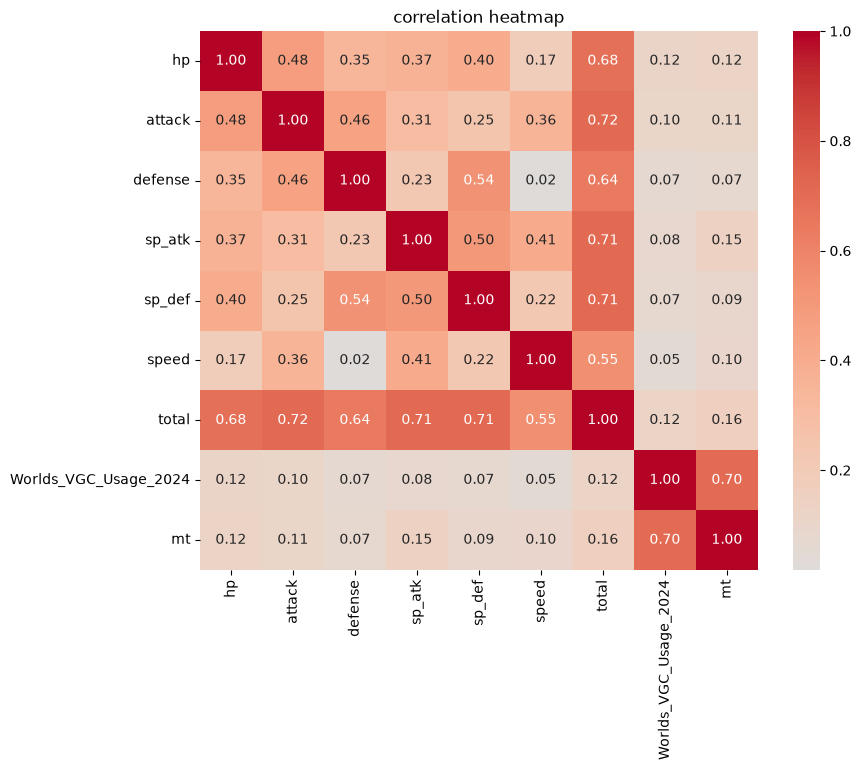

mt                       1.00
Worlds_VGC_Usage_2024    0.70
total                    0.16
sp_atk                   0.15
hp                       0.12
attack                   0.11
speed                    0.10
sp_def                   0.09
defense                  0.07
Name: mt, dtype: float64


In [26]:
# covariance and correlation
print(d[cols + ["mt"]].cov().round(2))
cr = d[cols + ["mt"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(cr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("correlation heatmap")
plt.show()
print(cr["mt"].sort_values(ascending=False).round(2))

tier
T4    1162
T3      28
T2      19
T1      12
Name: count, dtype: int64


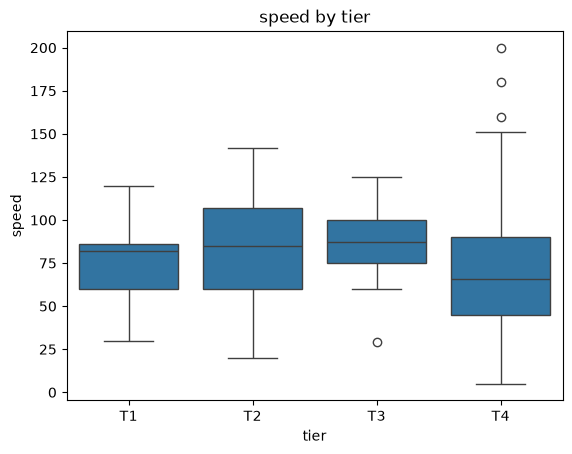

In [27]:
# usage tiers
def tier(u):
    if u >= 15: return "T1"
    if u >= 5: return "T2"
    if u >= 1: return "T3"
    return "T4"
d["tier"] = d["Worlds_VGC_Usage_2024"].apply(tier)
print(d["tier"].value_counts())
sns.boxplot(data=d, x="tier", y="speed", order=["T1", "T2", "T3", "T4"])
plt.title("speed by tier")
plt.show()

# Preprocessing, split, scaling, feature selection

In [28]:
# types and abilities -> 0/1 columns
def multi(cols, pre):
    col_dict = {}
    for c in cols:
        v = d[c].fillna("none").astype(str).str.strip().str.lower()
        for t in v.unique():
            if t in ["none", "nan", "", "no_ability"]:
                continue
            col_name = pre + t
            mask = (v == t).astype(int)
            # If the column name already exists, combine them
            if col_name in col_dict:
                col_dict[col_name] = col_dict[col_name] | mask
            else:
                col_dict[col_name] = mask
                
    # Create the DataFrame all at once to avoid fragmentation warnings
    return pd.DataFrame(col_dict, index=d.index)

In [29]:
tdum = multi(["type1", "type2"], "t_")
adum = multi(["ability1", "ability2", "hidden_ability"], "a_")
adum = adum.loc[:, adum.sum() >= 10]    # keep abilities that 10+ pokemon have
print(tdum.shape, adum.shape)

(1221, 19) (1221, 106)


In [30]:
# total is not used because it is just the sum of the 6 stats
X = pd.concat([d[st], d[["legendary", "mythical"]].astype(int), tdum, adum], axis=1)
y = d["mt"]
print("X shape:", X.shape)
print("missing values:", X.isna().sum().sum())

X shape: (1221, 133)
missing values: 0


In [31]:
# train test split 80/20
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("train:", Xtr.shape, "test:", Xte.shape)
print("meta in train:", round(ytr.mean(), 3), "meta in test:", round(yte.mean(), 3))

train: (976, 133) test: (245, 133)
meta in train: 0.048 meta in test: 0.049


In [32]:
# normalization (fit only on train)
sc = StandardScaler()
Xtr_s = pd.DataFrame(sc.fit_transform(Xtr), columns=X.columns, index=Xtr.index)
Xte_s = pd.DataFrame(sc.transform(Xte), columns=X.columns, index=Xte.index)
print(Xtr_s[st].describe().loc[["mean", "std"]].round(2))

       hp  attack  defense  sp_atk  sp_def  speed
mean -0.0    -0.0     -0.0    -0.0    -0.0    0.0
std   1.0     1.0      1.0     1.0     1.0    1.0


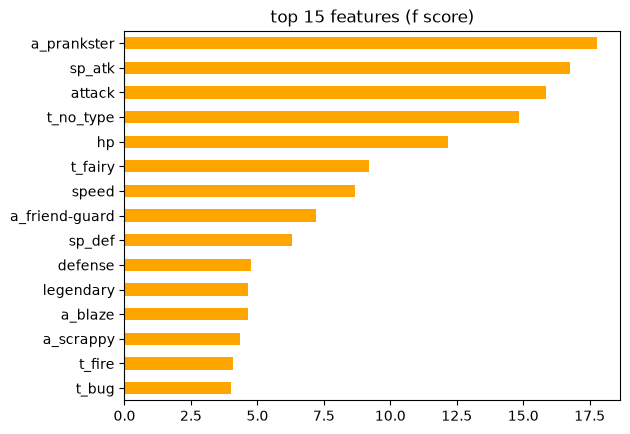

In [33]:
# feature selection (best 25 + the 6 stats always kept)
sel = SelectKBest(f_classif, k=25)
sel.fit(Xtr_s, ytr)
fs = pd.Series(sel.scores_, index=X.columns).sort_values(ascending=False)
fs.head(15).sort_values().plot(kind="barh", color="orange")
plt.title("top 15 features (f score)")
plt.show()

In [34]:
fc = list(X.columns[sel.get_support()])
fc = list(dict.fromkeys(st + fc))
print(len(fc), "features selected:", fc)
Xtr_f = Xtr_s[fc]
Xte_f = Xte_s[fc]

25 features selected: ['hp', 'attack', 'defense', 'sp_atk', 'sp_def', 'speed', 'legendary', 't_fire', 't_bug', 't_dark', 't_fairy', 't_fighting', 't_dragon', 't_no_type', 'a_blaze', 'a_run-away', 'a_vital-spirit', 'a_synchronize', 'a_poison-touch', 'a_flame-body', 'a_mold-breaker', 'a_unaware', 'a_prankster', 'a_friend-guard', 'a_scrappy']
